# 02 · Limpieza y suavizado satelital — Reto AgroCebada 2026

## Qué hace este cuaderno
Los satélites observan cada parcela cada pocos días, pero muchas de esas observaciones están dañadas: las nubes ocultan el campo, sus sombras lo oscurecen y la bruma reduce la señal de vegetación. Si calculáramos variables (verdor máximo, fecha de emergencia…) directamente con los puntos crudos, cada nube se convertiría en una falsa «caída de vigor». Este cuaderno convierte las observaciones irregulares y ruidosas de cada parcela en **una curva diaria limpia por índice**, para cada sensor por separado, y documenta cada punto que elimina y por qué.

## Los tres problemas y cómo resolvemos cada uno

| Problema | Cómo se ve | Nuestra solución (paso) |
|---|---|---|
| Imágenes total o mayormente nubladas | filas sin valores o con valores jalados hacia abajo | **B–D:** conservar imágenes hasta un umbral de nubosidad elegido con una prueba y dar menos peso a las parcialmente nubladas |
| Nubes y sombras no detectadas | puntos aislados muy *por debajo* de la curva | **C:** un suavizador robusto que detecta y rechaza los puntos demasiado lejanos de la curva y vuelve a suavizar |
| Fechas irregulares y huecos | de 1 a 20 días entre imágenes | **C–E:** un suavizador de Whittaker que produce un valor para cada día y registra qué tan lejos está cada día de una observación real |

## Reglas
- **Los sensores nunca se mezclan.** Planet, Sentinel-2 y Landsat tienen cada uno sus propias curvas (el diccionario de índices lo exige: mismos nombres de índice, instrumentos distintos).
- **Cada parámetro se elige con una prueba sobre los datos.** Ocultamos observaciones reales despejadas, reconstruimos la curva sin ellas y nos quedamos con la configuración que mejor predice los puntos ocultos.
- **Nada en este cuaderno usa el rendimiento.** Las parcelas de entrenamiento y de predicción se procesan igual, así que no hay fuga de información.
- **No se borra nada del disco.** Cada observación conserva una etiqueta de estado (`ok`, `spike`, `cloud_over_threshold`, `empty`) en `interim/sat_obs_qc.parquet`.

## Entradas (del cuaderno 01)
`interim/pro_obs.parquet` (Planet 2025), `interim/basic_obs.parquet` (Sentinel-2 + Landsat 2022–2025), `interim/plots_attributes.csv`.

## Salidas
| Archivo | Contenido |
|---|---|
| `interim/daily_planet.parquet` | una fila por parcela × día (2025): NDVI, EVI, LAI y MSAVI suavizados + `gap_days` |
| `interim/daily_sentinel2.parquet` | una fila por parcela × día (2022–2025): 22 índices suavizados + `gap_days` |
| `interim/daily_landsat.parquet` | una fila por parcela × día (2022–2025): VI6T suavizado + `gap_days` |
| `interim/sat_obs_qc.parquet` | cada observación original con su estado, peso y residuo |
| `qa/nb02_*.csv`, `qa/figures/nb02_*.png`, `qa/nb02_report.md` | resultados del ajuste, tablas de control, figuras y reporte |

**Tiempo de ejecución:** unos 5–10 minutos en una CPU estándar de Colab.

## 0 · Preparación
Misma estructura de carpetas que el cuaderno 01. El diccionario `CONFIG` contiene cada decisión fijada *antes* de ver resultados; todo lo demás se elige con las pruebas del paso D.

In [1]:
# 0.1 · Librerías, Drive y rutas
import os, json, time, warnings, platform
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.sparse.linalg import splu
import matplotlib
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

BASE = Path("/content/drive/MyDrive/AgroCebada") if IN_COLAB else Path(os.environ.get("AGC_BASE", "AgroCebada"))
INTERIM, QA = BASE / "interim", BASE / "qa"
FIG = QA / "figures"
FIG.mkdir(parents=True, exist_ok=True)
for f in ["pro_obs.parquet", "basic_obs.parquet", "plots_attributes.csv"]:
    assert (INTERIM / f).exists(), f"Falta {INTERIM / f}: ejecuta primero el cuaderno 01."

SEED = 42
RNG = np.random.default_rng(SEED)
if "display" not in globals():
    display = print
print(f"BASE = {BASE} | Colab: {IN_COLAB} | pandas {pd.__version__}")

Mounted at /content/drive
BASE = /content/drive/MyDrive/AgroCebada | Colab: True | pandas 2.2.3


In [2]:
# 0.2 · Configuración fija (decidida antes de ver cualquier resultado)
SEASON_MONTHS = [6, 7, 8, 9, 10, 11]   # junio–noviembre: del reverdecimiento a la senescencia (auditoría del NB01)

CONFIG = {
    # sensor: índices a suavizar, índice para detectar picos anómalos, dirección del efecto de las nubes y malla diaria
    "Planet": {
        "source": "pro", "indices": ["ndvi", "evi", "lai", "msavi"], "spike_index": "ndvi",
        "asymmetric": True,                       # nubes y sombras BAJAN el NDVI → más estricto con las caídas
        "start": "2025-01-01", "end": "2025-12-31",
    },
    "Sentinel-2": {
        "source": "basic", "indices": None,       # None = todos los índices que trae este sensor
        "spike_index": "ndvi", "asymmetric": True,
        "start": "2022-01-01", "end": "2025-12-31",
    },
    "Landsat": {
        "source": "basic", "indices": None, "spike_index": "vi6t",
        "asymmetric": False,                      # VI6T mezcla óptico y térmico: la dirección del efecto de las nubes es desconocida
        "start": "2022-01-01", "end": "2025-12-31",
    },
}

CLOUD_CANDIDATES = [0, 10, 30, 50, 70, 90]          # umbrales probados en el paso D
LAMBDA_GRID = [10 ** e for e in np.arange(0.5, 4.51, 0.5)]   # intensidades de suavizado probadas en el paso D
K_NEG, K_POS, K_SYM = 4.0, 6.0, 4.0                  # rechazo de picos: residuo más allá de k DE robustas
ROBUST_ITERS = 5
TUNE_PLOTS, TUNE_REPS = 40, 3
BLOCK_DAYS, BLOCKS_PER_SEASON = 10, 3                # prueba de ocultamiento: se ocultan tres tramos de 10 días por temporada
N_BOOT = 300                                         # remuestreos bootstrap (por parcela) para el error estándar
FENCE = 1.0                                          # filtro de valores: fuera de P1 − 1×(P99−P1) o P99 + 1×(P99−P1)

COLORS = {"Planet": "#2a78d6", "Sentinel-2": "#eb6834", "Landsat": "#1baf7a"}   # color fijo por sensor en todas las figuras
MUNI_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
GREY, RED, INK = "#9a9a94", "#e34948", "#2b2b28"
# meses en español para los ejes de las figuras
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
FMT_MES = matplotlib.ticker.FuncFormatter(lambda x, _: MESES[matplotlib.dates.num2date(x).month - 1])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#b8b7ae", "axes.labelcolor": INK, "xtick.color": "#6b6b66",
                     "ytick.color": "#6b6b66", "font.size": 9, "legend.frameon": False})
CHECKS = []
def check(name, ok, detail="", warn_only=True, info=False):
    status = "INFO" if info else ("PASS" if ok else ("WARN" if warn_only else "FAIL"))
    rec = {"check": name, "status": status, "detail": str(detail)}
    for j, r in enumerate(CHECKS):
        if r["check"] == name:
            CHECKS[j] = rec
            break
    else:
        CHECKS.append(rec)
    print(f"[{status}] {name}" + (f" — {detail}" if detail != "" else ""))

## 1 · Cargar las tablas auditadas y separarlas por sensor

El cuaderno 01 ya interpretó las fechas (día primero) y normalizó los nombres de sensor. Aquí solo separamos las observaciones en tres tablas, una por sensor, y conservamos para cada sensor los índices que trae realmente (la auditoría mostró que Landsat solo trae VI6T y Sentinel-2 trae los otros 22).

In [3]:
# 1.1 · Carga y separación
pro = pd.read_parquet(INTERIM / "pro_obs.parquet")
basic = pd.read_parquet(INTERIM / "basic_obs.parquet")
plots = pd.read_csv(INTERIM / "plots_attributes.csv")
src_tables = {"pro": pro, "basic": basic}

OBS = {}
for sensor, cfg in CONFIG.items():
    df = src_tables[cfg["source"]]
    df = df[df.sensor == sensor].copy()
    mean_cols = [c for c in df.columns if c.endswith("_promedio")]
    non_empty = df[mean_cols].notna().any(axis=1)
    # un sensor "trae" un índice si aparece en al menos 5 % de sus imágenes no vacías
    carried = [c.replace("_promedio", "") for c in mean_cols if df.loc[non_empty, c].notna().mean() >= 0.05]
    cfg["indices"] = [i for i in (cfg["indices"] or carried) if i in carried]
    assert cfg["spike_index"] in cfg["indices"], f"{sensor}: no se encontró el índice de picos {cfg['spike_index']}"
    df["cloud"] = df["cloud"].fillna(0).clip(0, 100)
    df["obs_id"] = np.arange(len(df))
    OBS[sensor] = df.sort_values(["ID_POLIGONO", "date"]).reset_index(drop=True)

summary = pd.DataFrame({s: {"rows": len(d), "plots": d.ID_POLIGONO.nunique(),
                            "first date": d.date.min().date(), "last date": d.date.max().date(),
                            "indices": len(CONFIG[s]["indices"])} for s, d in OBS.items()}).T
display(summary)
for s, cfg in CONFIG.items():
    print(f"{s}: {cfg['indices']}")

             rows plots  first date   last date indices
Planet      47804   197  2025-01-01  2025-12-30       4
Sentinel-2  59040   197  2022-01-01  2025-12-31      22
Landsat     48626   197  2022-01-05  2025-12-31       1
Planet: ['ndvi', 'evi', 'lai', 'msavi']
Sentinel-2: ['ndvi', 'evi', 'crc', 'mcrc', 'ndsvi', 'srndi', 'mra', 'lai', 'fapar', 'savi', 'ndti', 'sti', 'ndwi', 'endwi', 'msi', 'emsi', 'dswi2', 'dswi3', 'dswi4', 'dswi5', 'nddi', 'enddi']
Landsat: ['vi6t']


## 2 · Paso A: quitar filas vacías y filtrar valores imposibles

**Filas vacías.** Cuando una imagen está 100 % nublada, el proveedor deja vacíos todos los índices. Esas filas no aportan información y se etiquetan como `empty`.

**Valores.**
1. El NDVI debe estar en [−1, 1] (es así por definición en cualquier diferencia normalizada de reflectancias).
2. Para cada índice tomamos el rango que contiene el 98 % central de sus valores (del percentil 1 al 99, P1–P99) y lo extendemos ese mismo ancho hacia cada lado. Un valor fuera de estas **cercas** se trata como un artefacto de procesamiento (por ejemplo, un índice de cociente que divide entre casi cero). Solo se borra ese *valor*; el resto de la observación se conserva.

**¿Por qué percentiles y no «mediana ± k desviaciones estándar»?** Casi todo el año estos campos son suelo desnudo, así que índices como LAI o EVI se quedan cerca de cero durante nueve meses y solo suben durante la temporada. Su distribución es muy asimétrica. Una regla centrada en la mediana trata como atípicos los valores reales del pico de la temporada; una versión anterior de este cuaderno lo hizo y eliminó 2.6 % de los valores de LAI de Sentinel-2, todos en el pico del cultivo. Las cercas por percentiles respetan la forma de la distribución: el pico real queda dentro de P1–P99 y los artefactos muy por fuera. Una verificación avisa si el filtro llega a eliminar más de 0.5 % de un índice.

In [4]:
# 2.1 · Filas vacías y filtro de valores
def robust_sd(x):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    return 1.4826 * np.median(np.abs(x - np.median(x))) if len(x) else np.nan

screen_rows = []
for sensor, df in OBS.items():
    idx_cols = [f"{i}_promedio" for i in CONFIG[sensor]["indices"]]
    df["status"] = np.where(df[idx_cols].isna().all(axis=1), "empty", "ok")
    for i in CONFIG[sensor]["indices"]:
        c = f"{i}_promedio"
        v = df.loc[df.status == "ok", c].dropna()
        p1, p99 = v.quantile(0.01), v.quantile(0.99)
        lo, hi = p1 - FENCE * (p99 - p1), p99 + FENCE * (p99 - p1)
        bad = df[c].notna() & ((df[c] < lo) | (df[c] > hi))
        if i == "ndvi":
            bad |= ~df[c].between(-1, 1) & df[c].notna()
        screen_rows.append({"sensor": sensor, "index": i, "p1": p1, "p99": p99, "lower_fence": lo, "upper_fence": hi,
                            "values_blanked": int(bad.sum()), "share_%": round(100 * bad.sum() / max(len(v), 1), 3)})
        df.loc[bad, c] = np.nan
    # si se borró el índice de picos, la observación no se puede revisar → se trata como inutilizable
    si = f"{CONFIG[sensor]['spike_index']}_promedio"
    df.loc[(df.status == "ok") & df[si].isna(), "status"] = "value_screened"
screen = pd.DataFrame(screen_rows)
screen.to_csv(QA / "nb02_value_screen.csv", index=False)
display(screen.sort_values("values_blanked", ascending=False).head(10).round(4))
heavy = screen[screen["share_%"] > 0.5]
check("el filtro de valores elimina ≤ 0.5 % de cualquier índice", heavy.empty,
      "; ".join(f"{r.sensor} {r['index']}: {r['share_%']:.2f} %" for _, r in heavy.iterrows()) if len(heavy)
      else f"máximo {screen['share_%'].max():.3f} % ({screen.loc[screen['share_%'].idxmax(), 'sensor']} {screen.loc[screen['share_%'].idxmax(), 'index']})")
display(pd.DataFrame({s: d.status.value_counts() for s, d in OBS.items()}).fillna(0).astype(int))

        sensor  index      p1     p99  lower_fence  upper_fence  values_blanked  share_%
8   Sentinel-2  ndsvi -0.0082  0.5050      -0.5215       1.0182              13    0.029
7   Sentinel-2   mcrc -0.0600  0.4840      -0.6040       1.0280              11    0.025
25  Sentinel-2  enddi -0.0030  0.2220      -0.2280       0.4470              11    0.025
11  Sentinel-2    lai -0.1300  1.2452      -1.5052       2.6205               6    0.013
26     Landsat   vi6t -0.6640 -0.5330      -0.7950      -0.4020               1    0.003
9   Sentinel-2  srndi -0.1960  0.3440      -0.7360       0.8840               1    0.002
2       Planet    lai  0.5220  2.9220      -1.8780       5.3220               0    0.000
6   Sentinel-2    crc -0.1490  0.4910      -0.7890       1.1310               0    0.000
1       Planet    evi  0.0910  0.5950      -0.4130       1.0990               0    0.000
0       Planet   ndvi  0.1640  0.8000      -0.4720       1.4360               0    0.000
[PASS] el filtro de v

## 3 · Paso B: ¿cuánto sesga realmente la nubosidad los valores?

Antes de elegir un umbral de nubosidad *medimos* el daño. Para cada parcela construimos una curva de referencia **solo con imágenes despejadas** (nubosidad = 0 %) y preguntamos: ¿qué tan lejos queda cada imagen de esa referencia, agrupando por su nubosidad reportada?

- Si las imágenes parcialmente nubladas quedan justo sobre la curva despejada, descartarlas desperdicia datos, y los datos escasean precisamente en la temporada de lluvias, cuando crece el cultivo.
- Si quedan claramente por debajo, hay que descartarlas o darles menos peso.

Esta tabla es un **diagnóstico** para entender los datos. El umbral real se elige con la prueba predictiva del paso D.

### El suavizador que se usa en todo el cuaderno: Whittaker robusto

**Suavizador de Whittaker** (Eilers, 2003). Imagina una regla flexible sobre un calendario con una casilla por día. Buscamos una curva *z* que (1) pase cerca de los puntos observados y (2) sea suave. Minimiza

$$\sum_i w_i\,(y_i - z_i)^2 \;+\; \lambda \sum_t (z_{t+1} - 2z_t + z_{t-1})^2$$

- el primer término acerca la curva a las observaciones, cada una con peso *wᵢ* (los días sin imagen tienen peso 0, así que la curva simplemente cruza el hueco);
- el segundo término penaliza la curvatura; **λ (lambda) fija la rigidez**: un λ pequeño sigue cada oscilación y uno grande da una curva rígida y suave.

Es un sistema lineal disperso por parcela, así que es rápido y exacto, maneja fechas irregulares y huecos de forma natural y no produce artefactos en los extremos como los promedios móviles.

**Versión robusta (rechazo de picos).** Las nubes que el proveedor no detectó producen puntos muy *por debajo* de la curva. Iteramos:
1. ajustar la curva con los pesos actuales;
2. medir el residuo de cada punto (observado − curva) y la DE robusta de los residuos de los puntos despejados;
3. rechazar los puntos con residuo menor a −4 DE o mayor a +6 DE (nubes y sombras bajan el NDVI, por eso somos más estrictos con las caídas; para VI6T de Landsat la regla es simétrica, ±4 DE);
4. volver a ajustar sin ellos; parar cuando nada cambia (a lo más 5 rondas).

**Pesos.** Una imagen con *c* % de nubosidad recibe peso 1 − c/100 (mínimo 0.1): una imagen despejada cuenta completa y una medio nublada cuenta la mitad.

In [5]:
# 3.1 · Funciones del suavizador (se usan en todos los pasos siguientes)
class DailyGrid:
    """Calendario diario de un sensor; guarda la matriz de penalización de suavidad."""
    def __init__(self, start, end):
        self.days = pd.date_range(start, end, freq="D")
        self.n = len(self.days)
        D = sparse.diags([np.ones(self.n - 2), -2 * np.ones(self.n - 2), np.ones(self.n - 2)],
                         [0, 1, 2], shape=(self.n - 2, self.n))
        self.P = (D.T @ D).tocsc()

def whittaker(grid, di, values, weights, lam):
    """Ajuste de Whittaker ponderado sobre la malla diaria. di = índice de día de cada observación.
    Varias observaciones del mismo día se combinan como media ponderada."""
    w = np.zeros(grid.n)
    wy = np.zeros(grid.n)
    np.add.at(w, di, weights)
    np.add.at(wy, di, weights * values)
    lu = splu((sparse.diags(w) + lam * grid.P).tocsc())
    return lu.solve(wy), lu, w

def robust_whittaker(grid, di, v, wc, clear, lam, asymmetric, floor_sd):
    """Rechazo iterativo de picos. Devuelve (curva, máscara de conservados, residuos, DE robusta)."""
    ok = np.ones(len(v), bool)
    for _ in range(ROBUST_ITERS):
        z, _, _ = whittaker(grid, di[ok], v[ok], wc[ok], lam)
        r = v - z[di]
        ref = clear & ok if (clear & ok).sum() >= 6 else ok
        sd = max(robust_sd(r[ref]), floor_sd)
        lo, hi = (-K_NEG * sd, K_POS * sd) if asymmetric else (-K_SYM * sd, K_SYM * sd)
        new_ok = (r >= lo) & (r <= hi)
        if (new_ok == ok).all():
            break
        ok = new_ok
    return z, ok, r, sd

def cloud_weight(cloud):
    return np.clip(1 - np.asarray(cloud, float) / 100, 0.1, 1.0)

GRIDS = {s: DailyGrid(c["start"], c["end"]) for s, c in CONFIG.items()}
# piso para la DE robusta: 2 % del rango típico del índice, para no marcar de más a las parcelas muy suaves
FLOOR_SD = {}
for s, df in OBS.items():
    v = df.loc[df.status == "ok", f"{CONFIG[s]['spike_index']}_promedio"]
    FLOOR_SD[s] = 0.02 * (v.quantile(0.95) - v.quantile(0.05))
print({s: round(f, 4) for s, f in FLOOR_SD.items()})

{'Planet': np.float64(0.0107), 'Sentinel-2': np.float64(0.01), 'Landsat': np.float64(0.0016)}


                          n  median_bias  share_big_drop
sensor     cloud_bin                                    
Landsat    0          27079       0.0001          0.0295
           1–10         578       0.0067          0.1298
           11–30        766       0.0078          0.1501
           31–50        668       0.0085          0.1557
           51–70        635       0.0083          0.1591
           71–90        709       0.0086          0.1848
           91–99        612       0.0118          0.1912
Planet     0          30317      -0.0003          0.0083
           1–10        1391      -0.0121          0.1682
           11–30        986      -0.0158          0.1876
           31–50        744      -0.0199          0.2473
           51–70        714      -0.0199          0.2703
           71–90        918      -0.0309          0.3519
           91–99        677      -0.0369          0.4328
Sentinel-2 0          36744       0.0000          0.0424
           1–10        2698    

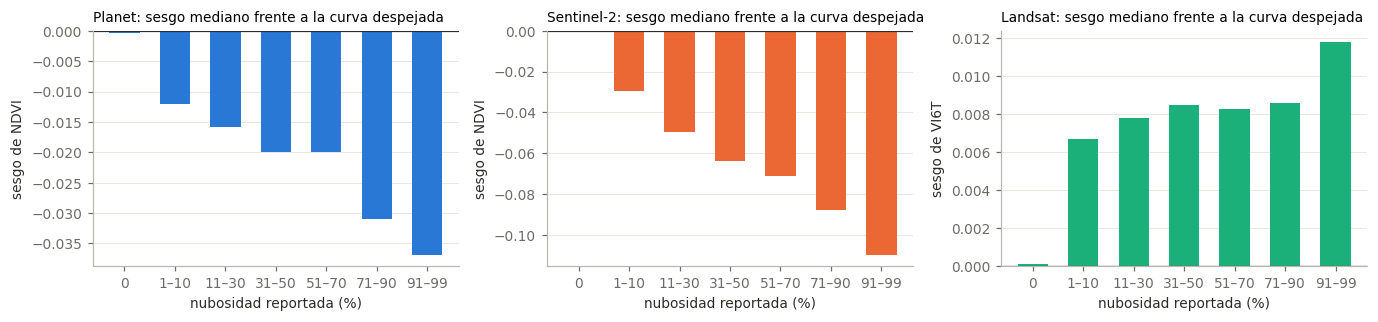

In [6]:
# 3.2 · Diagnóstico: sesgo de las imágenes parcialmente nubladas respecto a la curva despejada
diag_rows = []
for sensor, df in OBS.items():
    grid, si = GRIDS[sensor], f"{CONFIG[sensor]['spike_index']}_promedio"
    usable = df[df.status == "ok"]
    for pid, g in usable.groupby("ID_POLIGONO"):
        clear = g[g.cloud == 0]
        if len(clear) < 6:
            continue
        di_c = (clear.date - grid.days[0]).dt.days.to_numpy()
        z, ok, _, _ = robust_whittaker(grid, di_c, clear[si].to_numpy(), np.ones(len(clear)),
                                       np.ones(len(clear), bool), 100.0, CONFIG[sensor]["asymmetric"], FLOOR_SD[sensor])
        di = (g.date - grid.days[0]).dt.days.to_numpy()
        dev = g[si].to_numpy() - z[di]
        diag_rows.append(pd.DataFrame({"sensor": sensor, "cloud": g.cloud.to_numpy(), "dev": dev,
                                       "is_clear": g.cloud.to_numpy() == 0}))
diag = pd.concat(diag_rows, ignore_index=True)
diag["cloud_bin"] = pd.cut(diag.cloud, [-0.1, 0, 10, 30, 50, 70, 90, 99.99], labels=["0", "1–10", "11–30", "31–50", "51–70", "71–90", "91–99"])
sd_clear = diag[diag.is_clear].groupby("sensor").dev.agg(robust_sd)
diag["big_drop"] = diag.dev < -3 * diag.sensor.map(sd_clear)
bias_tab = (diag.groupby(["sensor", "cloud_bin"], observed=True)
                .agg(n=("dev", "size"), median_bias=("dev", "median"), share_big_drop=("big_drop", "mean"))
                .round(4))
bias_tab.to_csv(QA / "nb02_cloud_bias.csv")
display(bias_tab)

fig, axes = plt.subplots(1, len(CONFIG), figsize=(4.2 * len(CONFIG), 3.0), sharey=False)
for ax, sensor in zip(np.atleast_1d(axes), CONFIG):
    t = bias_tab.loc[sensor].reset_index() if sensor in bias_tab.index.get_level_values(0) else None
    if t is None:
        continue
    ax.bar(t.cloud_bin.astype(str), t.median_bias, color=COLORS[sensor], width=0.6)
    ax.grid(axis="x", visible=False)
    ax.axhline(0, color=INK, lw=0.8)
    ax.set_title(f"{sensor}: sesgo mediano frente a la curva despejada", fontsize=9, loc="left")
    ax.set_xlabel("nubosidad reportada (%)")
    ax.set_ylabel(f"sesgo de {CONFIG[sensor]['spike_index'].upper()}")
fig.tight_layout()
fig.savefig(FIG / "nb02_cloud_bias.png", bbox_inches="tight")
plt.show()

**Cómo leerla.** Cada barra es la diferencia típica entre las imágenes de esa clase de nubosidad y la curva despejada. Las barras cercanas a cero indican imágenes utilizables. En Planet, las imágenes con 1–50 % de nubosidad quedaron solo entre 0.012 y 0.020 de NDVI por debajo, mientras que las de más de 70 % quedaron claramente peor (≈ 0.03–0.04 abajo). Las imágenes parcialmente nubladas sí aportan información, pero deben contar menos que las despejadas, que es justo lo que hacen los pesos. `share_big_drop` es la fracción de imágenes más de 3 DE por debajo de la curva: los picos que atrapará el suavizador robusto.

## 4 · Paso C: el suavizador robusto en una parcela

Antes de aplicarlo a todo, veamos qué hace en una sola parcela: los puntos de color son las imágenes conservadas, las cruces grises son imágenes por encima del umbral provisional de nubosidad, las cruces rojas son picos rechazados por el ciclo robusto y la línea es la curva diaria.

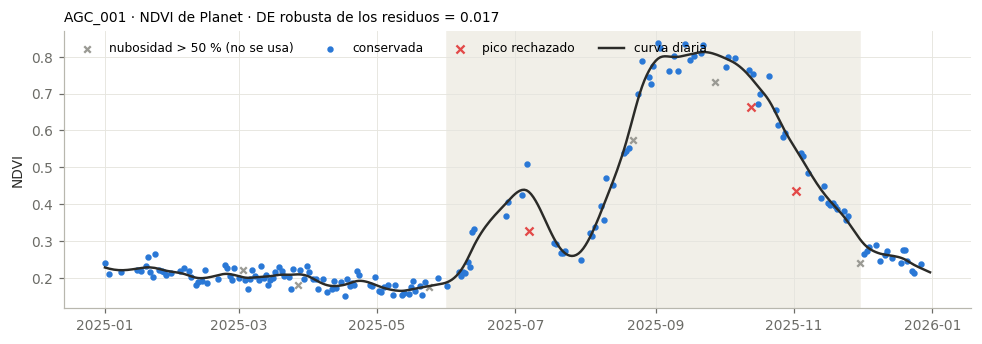

3 picos rechazados de 176 imágenes usadas


In [7]:
# 4.1 · Demostración en una parcela de entrenamiento (Planet, configuración provisional: nubosidad ≤ 50 %, λ = 100)
demo_id = plots.loc[plots.is_train, "ID_POLIGONO"].iloc[0]
sensor = "Planet"
grid, si = GRIDS[sensor], "ndvi_promedio"
g = OBS[sensor]
g = g[(g.ID_POLIGONO == demo_id) & (g.status == "ok")]
use = g.cloud <= 50
di = (g.date - grid.days[0]).dt.days.to_numpy()
z, ok, r, sd = robust_whittaker(grid, di[use], g[si].to_numpy()[use], cloud_weight(g.cloud[use]),
                                (g.cloud[use] == 0).to_numpy(), 100.0, True, FLOOR_SD[sensor])
fig, ax = plt.subplots(figsize=(9, 3.2))
gu = g[use]
ax.scatter(g.date[~use], g[si][~use], marker="x", s=18, color=GREY, label="nubosidad > 50 % (no se usa)")
ax.scatter(gu.date[ok], gu[si][ok], s=10, color=COLORS[sensor], label="conservada")
ax.scatter(gu.date[~ok], gu[si][~ok], marker="x", s=28, color=RED, label="pico rechazado")
ax.plot(grid.days, z, color=INK, lw=1.6, label="curva diaria")
ax.axvspan(pd.Timestamp("2025-06-01"), pd.Timestamp("2025-11-30"), color="#f1efe8", zorder=0)
ax.set_title(f"{demo_id} · NDVI de Planet · DE robusta de los residuos = {sd:.3f}", loc="left", fontsize=9)
ax.set_ylabel("NDVI"); ax.legend(ncol=4, fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "nb02_demo_plot.png", bbox_inches="tight"); plt.show()
print(f"{(~ok).sum()} picos rechazados de {use.sum()} imágenes usadas")

## 5 · Paso D: elegir el umbral de nubosidad y la intensidad del suavizado con una prueba

Dos parámetros importan: **el umbral de nubosidad** (qué imágenes entran) y **λ** (qué tan rígida es la curva). En lugar de suponerlos, hacemos una prueba de ocultamiento por sensor:

1. elegir 40 parcelas al azar;
2. en cada temporada de cultivo (junio–noviembre) de cada parcela, **ocultar tres tramos aleatorios de 10 días** de imágenes despejadas (nubosidad = 0 %); estas imágenes ocultas son nuestra verdad de referencia;
3. para cada combinación de umbral (0, 10, 30, 50, 70, 90 %) y λ (10^0.5 … 10^4.5), reconstruir la curva *sin* las imágenes ocultas;
4. medir qué tan bien predice la curva las imágenes ocultas (RMSE); λ se prueba desde 10^0.5 ≈ 3 hasta 10^4.5 ≈ 31,600, y una verificación avisa si el ganador queda en un extremo de ese rango (el óptimo real podría estar fuera);
5. repetir 3 veces con tramos ocultos distintos.

**¿Por qué ocultar tramos completos y no imágenes sueltas?** Planet observa una parcela casi a diario. Una imagen oculta suelta siempre tiene vecinas a un día de distancia, así que la prueba premiaría una curva que solo copia a sus vecinas (demasiado flexible). La dificultad real es cruzar los huecos de varios días de la temporada de lluvias, y ocultar tramos de 10 días prueba justo eso. (En una exploración con los datos reales de Planet, ocultar imágenes sueltas elegía λ = 10; ocultar tramos elige λ ≈ 100.)

**Regla de selección.** (1) λ = el valor con menor error. (2) Con ese λ, el umbral de nubosidad **más estricto** cuyo error esté a menos de un error estándar del mejor: cuando dos configuraciones empatan estadísticamente, preferimos la que admite menos imágenes nubladas. Como todas las configuraciones se evalúan con las mismas imágenes ocultas, la medida correcta es el error estándar de la diferencia entre dos configuraciones (comparación pareada), estimado remuestreando parcelas completas 300 veces (los errores de una misma parcela no son independientes). La columna de sesgo verifica que la configuración elegida no suba ni baje la curva de forma sistemática.

In [8]:
# 5.1 · Ajuste por ocultamiento de tramos de 10 días (≈ 2–5 min)
def tune_sensor(sensor):
    grid, cfg = GRIDS[sensor], CONFIG[sensor]
    si = f"{cfg['spike_index']}_promedio"
    df = OBS[sensor][OBS[sensor].status == "ok"]
    ids = [p for p, g in df.groupby("ID_POLIGONO") if (g.cloud == 0).sum() >= 10]
    ids = RNG.choice(ids, size=min(TUNE_PLOTS, len(ids)), replace=False)
    years = sorted(df.date.dt.year.unique())
    season_starts = [(pd.Timestamp(f"{y}-{SEASON_MONTHS[0]:02d}-01") - grid.days[0]).days for y in years]
    season_len = (pd.Timestamp(f"2025-{SEASON_MONTHS[-1]:02d}-30") - pd.Timestamp(f"2025-{SEASON_MONTHS[0]:02d}-01")).days
    errs = {(t, l): {} for t in CLOUD_CANDIDATES for l in LAMBDA_GRID}   # configuración -> {parcela: errores}
    for k, pid in enumerate(ids):
        g = df[df.ID_POLIGONO == pid]
        di = (g.date - grid.days[0]).dt.days.to_numpy()
        v, cl = g[si].to_numpy(), g.cloud.to_numpy()
        for _ in range(TUNE_REPS):
            hold = np.zeros(len(g), bool)
            for s0 in season_starts:
                for b in RNG.choice(np.arange(0, season_len - BLOCK_DAYS), BLOCKS_PER_SEASON, replace=False):
                    hold |= (cl == 0) & (di >= s0 + b) & (di < s0 + b + BLOCK_DAYS)
            # todas las configuraciones deben evaluarse con exactamente las mismas imágenes ocultas (comparación pareada)
            if not hold.any() or ((cl <= min(CLOUD_CANDIDATES)) & ~hold).sum() < 6:
                continue
            for t in CLOUD_CANDIDATES:
                use = (cl <= t) & ~hold
                for l in LAMBDA_GRID:
                    z, _, _, _ = robust_whittaker(grid, di[use], v[use], cloud_weight(cl[use]), cl[use] == 0,
                                                  l, cfg["asymmetric"], FLOOR_SD[sensor])
                    errs[(t, l)].setdefault(k, []).extend(z[di[hold]] - v[hold])
    rows = []
    for (t, l), by_plot in errs.items():
        e = np.concatenate([np.asarray(x) for x in by_plot.values()]) if by_plot else np.array([])
        rows.append({"sensor": sensor, "cloud_max": t, "log10_lambda": round(np.log10(l), 1), "lambda": l,
                     "n": len(e), "rmse": np.sqrt(np.mean(e ** 2)) if len(e) else np.nan,
                     "mae": np.mean(np.abs(e)) if len(e) else np.nan, "bias": np.mean(e) if len(e) else np.nan})
    return pd.DataFrame(rows), errs

def paired_se(errs_a, errs_b):
    """Error estándar de RMSE(a) − RMSE(b) cuando ambos se evalúan con las mismas imágenes ocultas;
    se remuestrean parcelas completas porque los errores de una misma parcela están correlacionados."""
    plots_ = sorted(set(errs_a) & set(errs_b))
    sa = {p: (np.sum(np.square(errs_a[p])), len(errs_a[p])) for p in plots_}
    sb = {p: (np.sum(np.square(errs_b[p])), len(errs_b[p])) for p in plots_}
    diffs = []
    for _ in range(N_BOOT):
        pick = RNG.choice(plots_, len(plots_), replace=True)
        ra = np.sqrt(sum(sa[p][0] for p in pick) / sum(sa[p][1] for p in pick))
        rb = np.sqrt(sum(sb[p][0] for p in pick) / sum(sb[p][1] for p in pick))
        diffs.append(ra - rb)
    return float(np.std(diffs))

t0 = time.time()
parts, CHOSEN = [], {}
for sensor in CONFIG:
    t, errs = tune_sensor(sensor)
    parts.append(t)
    t = t.dropna(subset=["rmse"])
    best = t.loc[t.rmse.idxmin()]
    bkey = (int(best.cloud_max), best["lambda"])
    lam_key = next(l for l in LAMBDA_GRID if np.isclose(l, best["lambda"]))
    pick, pick_se = best, 0.0
    for thr in sorted(CLOUD_CANDIDATES):                 # primero el más estricto
        if thr >= best.cloud_max:
            break
        row = t[(t.cloud_max == thr) & np.isclose(t["lambda"], lam_key)].iloc[0]
        se_d = paired_se(errs[(thr, lam_key)], errs[(int(best.cloud_max), lam_key)])
        if row.rmse - best.rmse <= se_d:                 # empate estadístico con el mejor → se toma el más estricto
            pick, pick_se = row, se_d
            break
    CHOSEN[sensor] = {"cloud_max": int(pick.cloud_max), "lambda": float(pick["lambda"]),
                      "rmse": float(pick.rmse), "bias": float(pick.bias),
                      "best_rmse": float(best.rmse), "best_cloud_max": int(best.cloud_max),
                      "se_of_difference": pick_se,
                      "rmse_cloud0_bestlambda": float(t[t.cloud_max == 0].rmse.min())}
tuning = pd.concat(parts, ignore_index=True)
tuning.to_csv(QA / "nb02_tuning.csv", index=False)
print(f"ajuste terminado en {time.time() - t0:.0f} s")
chosen_df = pd.DataFrame(CHOSEN).T
display(chosen_df.round(4))

ajuste terminado en 67 s
            cloud_max   lambda    rmse    bias  best_rmse  best_cloud_max  se_of_difference  rmse_cloud0_bestlambda
Planet           70.0    100.0  0.0458 -0.0049     0.0456            90.0            0.0002                  0.0481
Sentinel-2       10.0    100.0  0.0540 -0.0021     0.0540            10.0            0.0000                  0.0557
Landsat          30.0  10000.0  0.0164 -0.0002     0.0164            30.0            0.0000                  0.0167


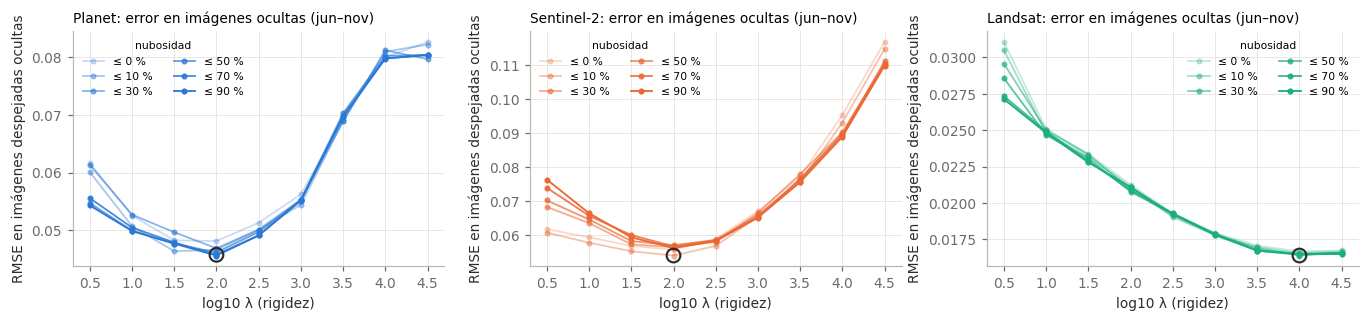

[INFO] Planet: configuración elegida por la prueba de ocultamiento — nubosidad ≤ 70 %, λ = 100; RMSE 0.0458 (mejor 0.0456 con ≤ 90 %) (solo imágenes despejadas: 0.0481); sesgo -0.0049
[PASS] Planet: la configuración elegida no tiene sesgo (|sesgo| < 0.25 × RMSE) — sesgo -0.0049
[PASS] Planet: el λ elegido está dentro del rango probado (no en un extremo) — λ = 100; probado 3–31623
[INFO] Sentinel-2: configuración elegida por la prueba de ocultamiento — nubosidad ≤ 10 %, λ = 100; RMSE 0.0540 (mejor 0.0540 con ≤ 10 %) (solo imágenes despejadas: 0.0557); sesgo -0.0021
[PASS] Sentinel-2: la configuración elegida no tiene sesgo (|sesgo| < 0.25 × RMSE) — sesgo -0.0021
[PASS] Sentinel-2: el λ elegido está dentro del rango probado (no en un extremo) — λ = 100; probado 3–31623
[INFO] Landsat: configuración elegida por la prueba de ocultamiento — nubosidad ≤ 30 %, λ = 10000; RMSE 0.0164 (mejor 0.0164 con ≤ 30 %) (solo imágenes despejadas: 0.0167); sesgo -0.0002
[PASS] Landsat: la configuración el

In [9]:
# 5.2 · Figura de los resultados del ajuste
fig, axes = plt.subplots(1, len(CONFIG), figsize=(4.2 * len(CONFIG), 3.0))
for ax, sensor in zip(np.atleast_1d(axes), CONFIG):
    t = tuning[tuning.sensor == sensor]
    for k, (thr, g) in enumerate(t.groupby("cloud_max")):
        shade = 0.25 + 0.75 * k / max(1, len(CLOUD_CANDIDATES) - 1)
        ax.plot(g.log10_lambda, g.rmse, marker="o", ms=3, lw=1.2,
                color=matplotlib.colors.to_rgba(COLORS[sensor], shade), label=f"≤ {thr} %")
    c = CHOSEN.get(sensor)
    if c:
        ax.scatter([np.log10(c["lambda"])], [c["rmse"]], s=80, facecolors="none", edgecolors=INK, lw=1.4, zorder=5)
    ax.set_title(f"{sensor}: error en imágenes ocultas (jun–nov)", loc="left", fontsize=9)
    ax.set_xlabel("log10 λ (rigidez)"); ax.set_ylabel("RMSE en imágenes despejadas ocultas")
    ax.legend(title="nubosidad", fontsize=7, title_fontsize=7, ncol=2)
fig.tight_layout(); fig.savefig(FIG / "nb02_tuning.png", bbox_inches="tight"); plt.show()
for s, c in CHOSEN.items():
    check(f"{s}: configuración elegida por la prueba de ocultamiento", True,
          f"nubosidad ≤ {c['cloud_max']} %, λ = {c['lambda']:.0f}; RMSE {c['rmse']:.4f} (mejor {c['best_rmse']:.4f} con ≤ {c['best_cloud_max']} %) "
          f"(solo imágenes despejadas: {c['rmse_cloud0_bestlambda']:.4f}); sesgo {c['bias']:+.4f}", info=True)
    check(f"{s}: la configuración elegida no tiene sesgo (|sesgo| < 0.25 × RMSE)", abs(c["bias"]) < 0.25 * c["rmse"], f"sesgo {c['bias']:+.4f}")
    at_edge = np.isclose(c["lambda"], max(LAMBDA_GRID)) or np.isclose(c["lambda"], min(LAMBDA_GRID))
    check(f"{s}: el λ elegido está dentro del rango probado (no en un extremo)", not at_edge,
          f"λ = {c['lambda']:.0f}; probado {min(LAMBDA_GRID):.0f}–{max(LAMBDA_GRID):.0f}")

**Cómo leerla.** Cada línea es un umbral de nubosidad; el eje x es λ. El punto encerrado es la configuración elegida. Las líneas más bajas son mejores. Si la línea «≤ 50 %» queda debajo de la línea «≤ 0 %», las imágenes parcialmente nubladas *ayudan*: añaden información en los meses de lluvia más de lo que añaden ruido. En la exploración con los datos reales de Planet ocurrió justo eso: error en tramos ocultos de 0.045 solo con imágenes despejadas, frente a 0.040 al admitir imágenes parcialmente nubladas con peso reducido (−12 %).

## 6 · Paso E: limpiar y suavizar todas las parcelas con la configuración elegida

Para cada sensor y cada parcela:
1. las imágenes por encima del umbral de nubosidad elegido reciben el estado `cloud_over_threshold`;
2. el suavizador robusto corre sobre el **índice de picos** (NDVI en Planet y Sentinel-2, VI6T en Landsat) y etiqueta como `spike` las imágenes rechazadas. Una nube afecta todas las bandas de la imagen, así que una imagen con pico se elimina de **todos** los índices, no solo del NDVI;
3. cada índice se suaviza con las mismas imágenes, pesos y λ, lo que da un valor por día;
4. dos protecciones contra artefactos: antes de la primera y después de la última imagen conservada, la curva se mantiene **plana** (si no, el suavizador prolonga la última tendencia como una recta; en los datos reales, una parcela sin imágenes útiles en sus últimos 60 días bajó a NDVI −0.3), y la curva no puede salir del rango observado de la propia parcela por más de 5 %;
5. `gap_days` = distancia de cada día a la imagen conservada más cercana. Un valor interpolado a través de un hueco de 40 días es menos confiable que uno entre dos imágenes separadas por 3 días; el cuaderno 03 lo usa para marcar ajustes fenológicos débiles.

In [10]:
# 6.1 · Aplicar a todas las parcelas (≈ 1–3 min)
def smooth_sensor(sensor):
    grid, cfg, ch = GRIDS[sensor], CONFIG[sensor], CHOSEN[sensor]
    df = OBS[sensor]
    si = f"{cfg['spike_index']}_promedio"
    idx_cols = [f"{i}_promedio" for i in cfg["indices"]]
    df.loc[(df.status == "ok") & (df.cloud > ch["cloud_max"]), "status"] = "cloud_over_threshold"
    df["weight"], df["residual"] = 0.0, np.nan
    daily_parts = []
    for pid, g in df.groupby("ID_POLIGONO"):
        u = g[g.status == "ok"]
        out = pd.DataFrame({"ID_POLIGONO": pid, "date": grid.days})
        if len(u) < 6:
            for c in idx_cols:
                out[c.replace("_promedio", "")] = np.nan
            out["gap_days"] = np.nan
            daily_parts.append(out)
            continue
        di = (u.date - grid.days[0]).dt.days.to_numpy()
        wc = cloud_weight(u.cloud)
        z, ok, r, sd = robust_whittaker(grid, di, u[si].to_numpy(), wc, (u.cloud == 0).to_numpy(),
                                        ch["lambda"], cfg["asymmetric"], FLOOR_SD[sensor])
        df.loc[u.index[~ok], "status"] = "spike"
        df.loc[u.index, "residual"] = r
        df.loc[u.index[ok], "weight"] = wc[ok]
        k = u[ok]
        dk = di[ok]
        # una factorización por cada patrón distinto de faltantes (normalmente solo uno)
        patterns = {}
        for c in idx_cols:
            m = k[c].notna().to_numpy()
            patterns.setdefault(m.tobytes(), (m, []))[1].append(c)
        for m, cols in patterns.values():
            if m.sum() < 6:
                for c in cols:
                    out[c.replace("_promedio", "")] = np.nan
                continue
            w = np.zeros(grid.n)
            np.add.at(w, dk[m], wc[ok][m])
            lu = splu((sparse.diags(w) + ch["lambda"] * grid.P).tocsc())
            WY = np.zeros((grid.n, len(cols)))
            for j, c in enumerate(cols):
                np.add.at(WY[:, j], dk[m], wc[ok][m] * k[c].to_numpy()[m])
            Z = lu.solve(WY)
            # protección 1: plana antes de la primera y después de la última imagen conservada (sin extrapolación lineal en los extremos)
            first, last = dk[m].min(), dk[m].max()
            Z[:first], Z[last + 1:] = Z[first], Z[last]
            # protección 2: dentro del rango observado de la parcela ± 5 % (sin rebases en huecos largos)
            for j, c in enumerate(cols):
                obs = k[c].to_numpy()[m]
                lo, hi = obs.min(), obs.max()
                out[c.replace("_promedio", "")] = np.clip(Z[:, j], lo - 0.05 * (hi - lo), hi + 0.05 * (hi - lo))
        kept_days = np.unique(dk)
        pos = np.searchsorted(kept_days, np.arange(grid.n))
        left = kept_days[np.clip(pos - 1, 0, len(kept_days) - 1)]
        right = kept_days[np.clip(pos, 0, len(kept_days) - 1)]
        out["gap_days"] = np.minimum(np.abs(np.arange(grid.n) - left), np.abs(right - np.arange(grid.n)))
        daily_parts.append(out)
    daily = pd.concat(daily_parts, ignore_index=True)
    float_cols = [c for c in daily.columns if c not in ("ID_POLIGONO", "date", "gap_days")]
    daily[float_cols] = daily[float_cols].astype("float32")
    daily["gap_days"] = daily["gap_days"].astype("float32")
    return daily

DAILY = {}
t0 = time.time()
for sensor in CONFIG:
    DAILY[sensor] = smooth_sensor(sensor)
    print(f"{sensor}: {DAILY[sensor].shape} en {time.time() - t0:.0f} s")
status_tab = pd.DataFrame({s: d.status.value_counts() for s, d in OBS.items()}).fillna(0).astype(int)
status_share = (100 * status_tab / status_tab.sum()).round(2)
display(pd.concat({"rows": status_tab, "%": status_share}, axis=1))

Planet: (71905, 7) en 1 s
Sentinel-2: (287817, 25) en 4 s
Landsat: (287817, 4) en 6 s
                       rows                         %                   
                     Planet Sentinel-2 Landsat Planet Sentinel-2 Landsat
status                                                                  
cloud_over_threshold   1595       5435    2624   3.34       9.21    5.40
empty                 12057      14163   17578  25.22      23.99   36.15
ok                    33791      38286   27128  70.69      64.85   55.79
spike                   361       1156    1295   0.76       1.96    2.66
value_screened            0          0       1   0.00       0.00    0.00


## 7 · Paso F: control de calidad. Ver las curvas y ponerlas a prueba

Los números solos pueden esconder problemas, así que revisamos visualmente *y* con pruebas:
- **12 parcelas al azar por sensor** con imágenes crudas, imágenes rechazadas y la curva diaria;
- **perfil estacional por municipio** (2025): todos los municipios deberían mostrar el mismo ritmo, bajo hasta mayo, reverdecimiento en junio–julio, pico en agosto–septiembre y senescencia en octubre–noviembre;
- **concordancia entre Planet y Sentinel-2**: dos satélites independientes deberían coincidir en la *forma* de la temporada 2025 de cada parcela (correlación alta), aunque sus niveles difieran (son instrumentos distintos, por eso nunca los mezclamos);
- **cobertura**: cuántas imágenes conservadas tiene cada parcela durante la temporada 2025 y su hueco más largo.

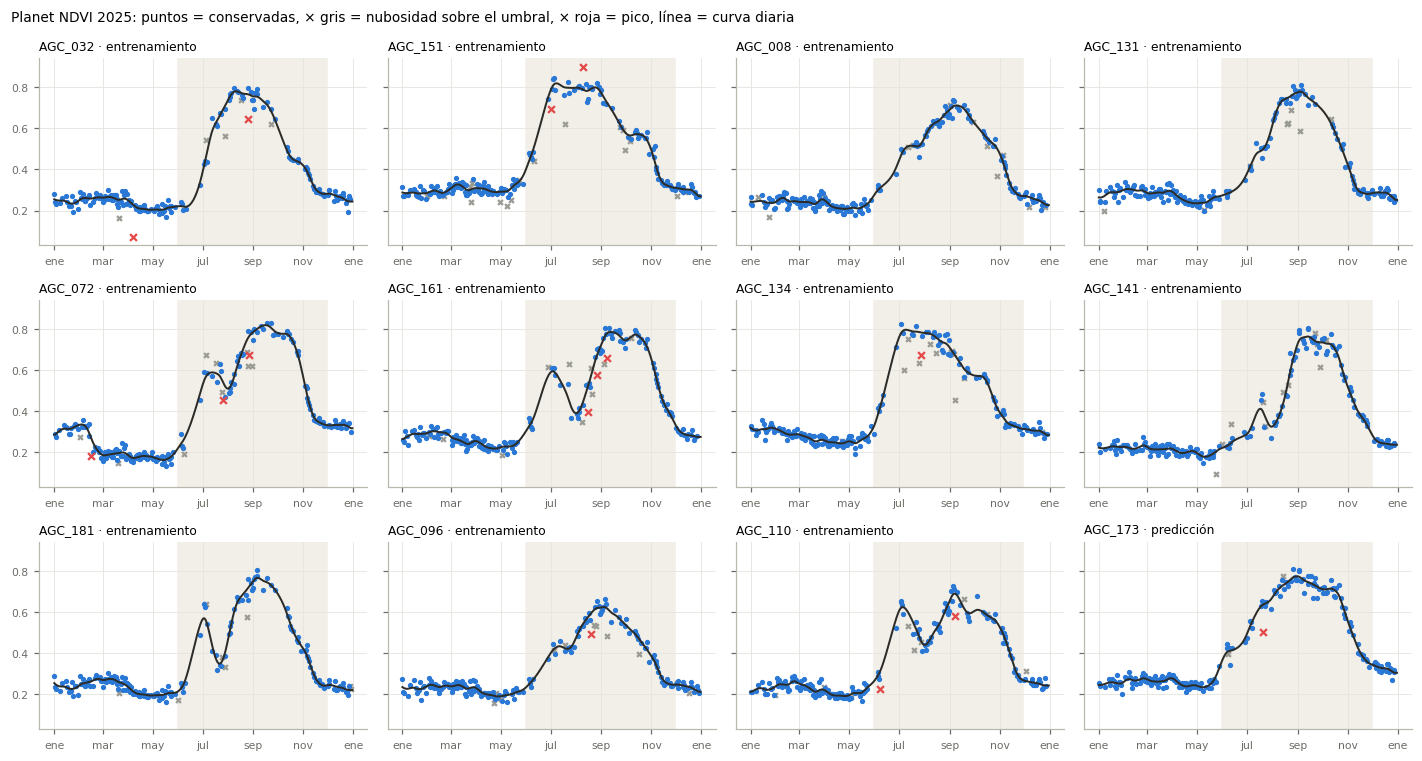

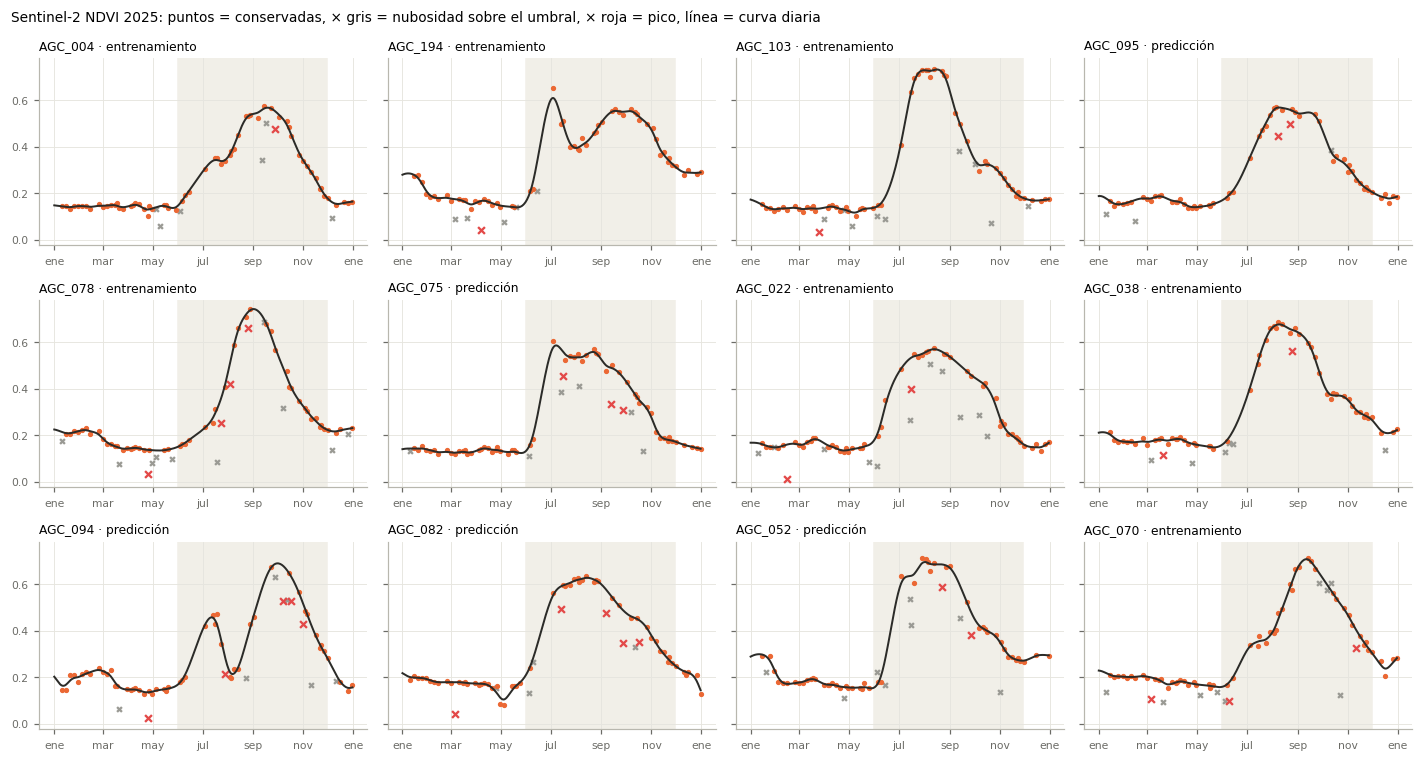

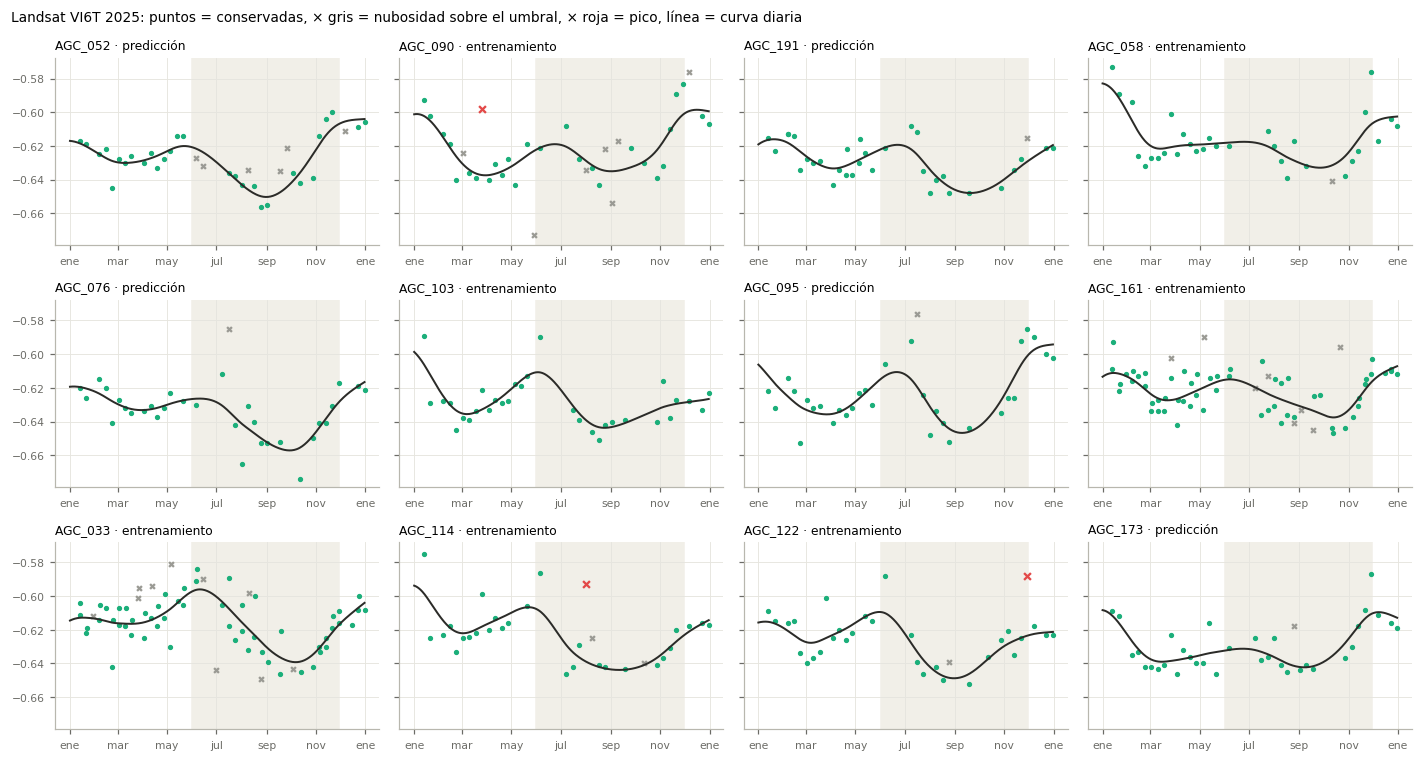

In [11]:
# 7.1 · Doce parcelas al azar por sensor
def plot_examples(sensor, n=12, year=2025):
    grid, si = GRIDS[sensor], CONFIG[sensor]["spike_index"]
    ids = RNG.choice(plots.ID_POLIGONO.to_numpy(), n, replace=False)
    fig, axes = plt.subplots(3, 4, figsize=(13, 7), sharey=True)
    lo, hi = pd.Timestamp(f"{year}-01-01"), pd.Timestamp(f"{year}-12-31")
    for ax, pid in zip(axes.ravel(), ids):
        o = OBS[sensor]
        o = o[(o.ID_POLIGONO == pid) & o.date.between(lo, hi)]
        d = DAILY[sensor]
        d = d[(d.ID_POLIGONO == pid) & d.date.between(lo, hi)]
        c = f"{si}_promedio"
        ax.scatter(o.date[o.status == "cloud_over_threshold"], o[c][o.status == "cloud_over_threshold"], marker="x", s=10, color=GREY)
        ax.scatter(o.date[o.status == "ok"], o[c][o.status == "ok"], s=6, color=COLORS[sensor])
        ax.scatter(o.date[o.status == "spike"], o[c][o.status == "spike"], marker="x", s=20, color=RED)
        ax.plot(d.date, d[si], color=INK, lw=1.3)
        ax.axvspan(pd.Timestamp(f"{year}-06-01"), pd.Timestamp(f"{year}-11-30"), color="#f1efe8", zorder=0)
        tr = plots.set_index("ID_POLIGONO").loc[pid, "is_train"]
        ax.set_title(f"{pid} · {'entrenamiento' if tr else 'predicción'}", fontsize=8, loc="left")
        ax.tick_params(labelsize=7)
        ax.xaxis.set_major_formatter(FMT_MES)
    fig.suptitle(f"{sensor} {si.upper()} {year}: puntos = conservadas, × gris = nubosidad sobre el umbral, × roja = pico, línea = curva diaria",
                 fontsize=9, x=0.01, ha="left")
    fig.tight_layout(); fig.savefig(FIG / f"nb02_examples_{sensor.replace('-', '').lower()}.png", bbox_inches="tight"); plt.show()

for sensor in CONFIG:
    plot_examples(sensor)

**Qué buscar en las parcelas de ejemplo.** La curva negra debe pasar por los puntos de color, ignorar las cruces rojas y mostrar una temporada clara por año. Algunas parcelas muestran **dos jorobas**: un primer reverdecimiento a finales de junio–julio, una caída y luego el pico principal en septiembre. Es real (maleza o rebrote después de las primeras lluvias, luego labranza y siembra), no un error del suavizado. Por eso el cuaderno 03 debe elegir el pico de la temporada **principal** y no simplemente el primero.

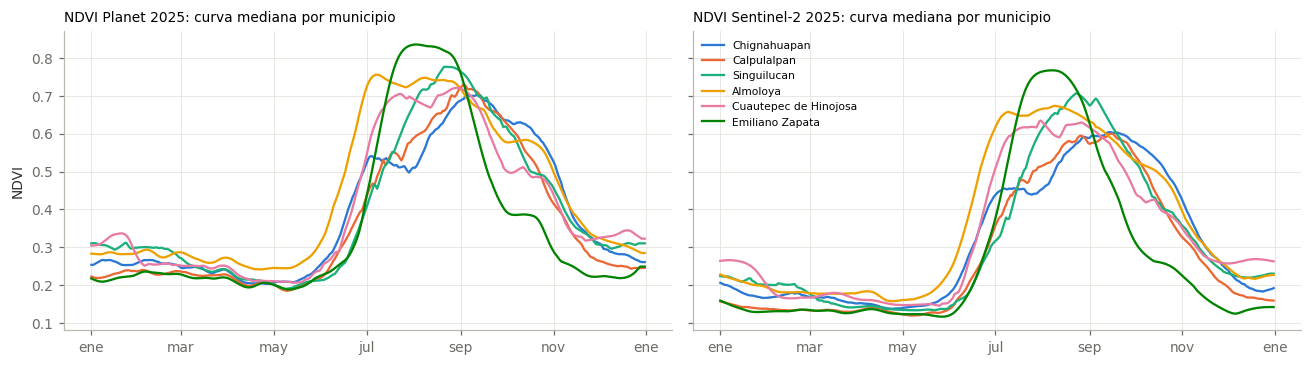

In [12]:
# 7.2 · Perfil estacional por municipio (2025, mediana de las parcelas)
top_munis = plots.Municipio.value_counts().index[:6].tolist()      # orden fijo = por número de parcelas
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, sensor in zip(axes, ["Planet", "Sentinel-2"]):
    d = DAILY[sensor]
    d = d[d.date.dt.year == 2025].merge(plots[["ID_POLIGONO", "Municipio"]], on="ID_POLIGONO")
    prof = d[d.Municipio.isin(top_munis)].groupby(["Municipio", "date"]).ndvi.median().unstack(0)
    for k, m in enumerate(top_munis):
        if m in prof:
            ax.plot(prof.index, prof[m], lw=1.5, color=MUNI_COLORS[k], label=m)
    ax.set_title(f"NDVI {sensor} 2025: curva mediana por municipio", loc="left", fontsize=9)
    ax.xaxis.set_major_formatter(FMT_MES)
axes[0].set_ylabel("NDVI"); axes[1].legend(fontsize=7, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "nb02_profiles_municipality.png", bbox_inches="tight"); plt.show()

**Qué buscar en los perfiles.** Todos los municipios deberían compartir el ritmo general (plano hasta mayo, reverdecimiento desde junio, senescencia hacia noviembre), pero **el momento y la altura cambian entre municipios**: en los datos de Planet, Almoloya reverdece primero, Emiliano Zapata alcanza el pico más alto y más temprano, y Chignahuapan (el municipio de mayor rendimiento) tiene la temporada más tardía y más larga. Estas diferencias de calendario son justo el tipo de señal que el cuaderno 03 convierte en variables.

/tmp/ipykernel_3832/1647227542.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  agree = both.groupby("ID_POLIGONO").apply(


             r  bias_s2_minus_planet  peak_day_diff
count  197.000               197.000        197.000
mean     0.986                -0.079         -0.305
std      0.022                 0.011         11.574
min      0.816                -0.122        -37.000
25%      0.986                -0.086         -6.000
50%      0.992                -0.079          0.000
75%      0.995                -0.073          4.000
max      0.999                -0.046         58.000


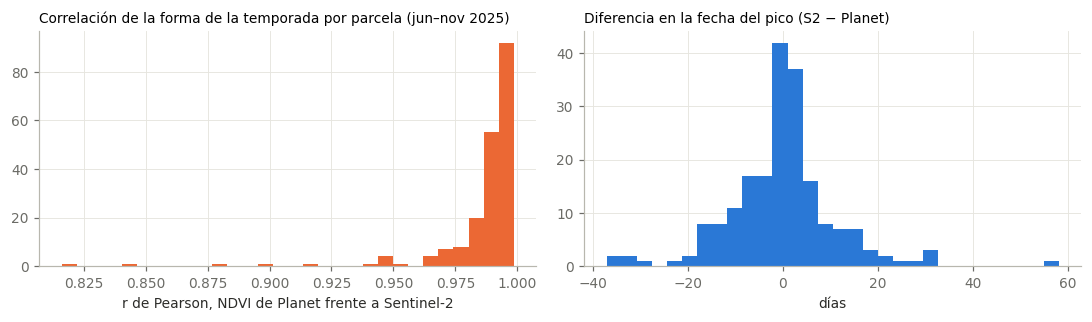

[PASS] Planet y Sentinel-2 coinciden en la forma de la temporada (r mediana ≥ 0.8) — r mediana = 0.992; parcelas con r < 0.6: 0; diferencia mediana de nivel S2 − Planet = -0.079; diferencia mediana en la fecha del pico = +0 d


In [13]:
# 7.3 · Concordancia entre Planet y Sentinel-2 en la temporada 2025
season = lambda d: d[(d.date.dt.year == 2025) & d.date.dt.month.isin(SEASON_MONTHS)]
pl = season(DAILY["Planet"])[["ID_POLIGONO", "date", "ndvi"]]
s2 = season(DAILY["Sentinel-2"])[["ID_POLIGONO", "date", "ndvi"]]
both = pl.merge(s2, on=["ID_POLIGONO", "date"], suffixes=("_planet", "_s2")).dropna()
agree = both.groupby("ID_POLIGONO").apply(
    lambda g: pd.Series({"r": np.corrcoef(g.ndvi_planet, g.ndvi_s2)[0, 1],
                         "bias_s2_minus_planet": (g.ndvi_s2 - g.ndvi_planet).mean(),
                         "peak_day_diff": int((g.date.iloc[g.ndvi_s2.argmax()] - g.date.iloc[g.ndvi_planet.argmax()]).days)}))
agree.to_csv(QA / "nb02_planet_vs_s2.csv")
display(agree.describe().round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(agree.r, bins=30, color=COLORS["Sentinel-2"])
axes[0].set_title("Correlación de la forma de la temporada por parcela (jun–nov 2025)", loc="left", fontsize=9)
axes[0].set_xlabel("r de Pearson, NDVI de Planet frente a Sentinel-2")
axes[1].hist(agree.peak_day_diff.clip(-60, 60), bins=30, color=COLORS["Planet"])
axes[1].set_title("Diferencia en la fecha del pico (S2 − Planet)", loc="left", fontsize=9)
axes[1].set_xlabel("días")
fig.tight_layout(); fig.savefig(FIG / "nb02_planet_vs_s2.png", bbox_inches="tight"); plt.show()
check("Planet y Sentinel-2 coinciden en la forma de la temporada (r mediana ≥ 0.8)", agree.r.median() >= 0.8,
      f"r mediana = {agree.r.median():.3f}; parcelas con r < 0.6: {int((agree.r < 0.6).sum())}; "
      f"diferencia mediana de nivel S2 − Planet = {agree.bias_s2_minus_planet.median():+.3f}; "
      f"diferencia mediana en la fecha del pico = {agree.peak_day_diff.median():+.0f} d")

In [14]:
# 7.4 · Pruebas de cobertura y verificaciones finales
S_START, S_END = pd.Timestamp(f"2025-{SEASON_MONTHS[0]:02d}-01"), pd.Timestamp("2025-11-30")
def longest_gap(dates):
    """Racha más larga de días sin imagen conservada dentro de la temporada 2025 (los bordes de la ventana cuentan)."""
    d = np.sort(np.unique(np.concatenate([[S_START.value], dates.values.astype("datetime64[ns]").astype("int64"), [S_END.value]])))
    return float(np.diff(d).max() / 8.64e13)

cov_rows = []
for sensor in CONFIG:
    o = OBS[sensor]
    o = o[(o.status == "ok") & o.date.between(S_START, S_END)]
    n = o.groupby("ID_POLIGONO").size().reindex(plots.ID_POLIGONO, fill_value=0)
    gap = o.groupby("ID_POLIGONO").date.apply(longest_gap).reindex(plots.ID_POLIGONO).fillna((S_END - S_START).days)
    cov_rows.append(pd.DataFrame({"sensor": sensor, "ID_POLIGONO": plots.ID_POLIGONO.to_numpy(),
                                  "season_images_2025": n.to_numpy(), "max_gap_days_2025": gap.to_numpy()}))
coverage = pd.concat(cov_rows, ignore_index=True)
coverage.to_csv(QA / "nb02_coverage.csv", index=False)
display(coverage.groupby("sensor")[["season_images_2025", "max_gap_days_2025"]].describe().round(1).T)

MAX_GAP = {"Planet": 30, "Sentinel-2": 45, "Landsat": 60}
for sensor in CONFIG:
    c = coverage[coverage.sensor == sensor]
    weak = c[(c.season_images_2025 < 5) | (c.max_gap_days_2025 > MAX_GAP[sensor])]
    check(f"{sensor}: toda parcela tiene ≥ 5 imágenes y ningún hueco > {MAX_GAP[sensor]} d en jun–nov 2025", weak.empty,
          f"{len(weak)} parcelas débiles: {weak.ID_POLIGONO.tolist()[:12]}" if len(weak) else
          f"mediana {c.season_images_2025.median():.0f} imágenes, hueco máximo mediano {c.max_gap_days_2025.median():.0f} d")
    d = DAILY[sensor]
    vals = d[CONFIG[sensor]["indices"]]
    check(f"{sensor}: curvas diarias completas (sin NaN)", bool(vals.notna().all().all()),
          f"{int(vals.isna().any(axis=1).sum())} parcela-días con NaN" if vals.isna().any().any() else f"{d.ID_POLIGONO.nunique()} parcelas × {GRIDS[sensor].n} días")
    st = OBS[sensor].status.value_counts(normalize=True)
    check(f"{sensor}: proporción de picos < 3 % de las imágenes", st.get("spike", 0) < 0.03, f"{100 * st.get('spike', 0):.2f} %")
for sensor in ["Planet", "Sentinel-2"]:
    nd = DAILY[sensor].ndvi
    check(f"{sensor}: NDVI suavizado dentro de [−0.2, 1.0]", bool(nd.between(-0.2, 1.0).all()), f"{nd.min():.3f} – {nd.max():.3f}")

sensor                    Landsat  Planet  Sentinel-2
season_images_2025 count    197.0   197.0       197.0
                   mean      13.7    62.9        26.6
                   std        3.6     7.7         2.0
                   min        7.0    43.0        21.0
                   25%       12.0    58.0        25.0
                   50%       13.0    63.0        27.0
                   75%       15.0    68.0        28.0
                   max       26.0    80.0        32.0
max_gap_days_2025  count    197.0   197.0       197.0
                   mean      42.4    19.0        24.6
                   std       12.4     3.7         3.7
                   min       24.0    14.0        20.0
                   25%       32.0    16.0        20.0
                   50%       40.0    19.0        25.0
                   75%       48.0    21.0        25.0
                   max       72.0    42.0        43.0
[WARN] Planet: toda parcela tiene ≥ 5 imágenes y ningún hueco > 30 d en jun–nov 20

In [15]:
# 7.5 · Las parcelas de entrenamiento y de predicción reciben el mismo trato (sin diferencias ocultas de calidad)
c = coverage.merge(plots[["ID_POLIGONO", "is_train"]], on="ID_POLIGONO")
tab = c.groupby(["sensor", "is_train"])[["season_images_2025", "max_gap_days_2025"]].median().unstack()
display(tab)
for sensor in CONFIG:
    t = c[c.sensor == sensor].groupby("is_train").season_images_2025.median()
    rel = abs(t.get(True, np.nan) - t.get(False, np.nan)) / max(t.max(), 1)
    check(f"{sensor}: las parcelas de entrenamiento y de predicción tienen cobertura similar (≤ 20 % de diferencia)", rel <= 0.2,
          f"imágenes medianas en temporada: entrenamiento {t.get(True, np.nan):.0f}, predicción {t.get(False, np.nan):.0f}")

           season_images_2025       max_gap_days_2025      
is_train                False True              False True 
sensor                                                     
Landsat                  12.0  13.0              40.0  40.0
Planet                   63.0  63.0              19.0  20.0
Sentinel-2               26.0  27.0              25.0  25.0
[PASS] Planet: las parcelas de entrenamiento y de predicción tienen cobertura similar (≤ 20 % de diferencia) — imágenes medianas en temporada: entrenamiento 63, predicción 63
[PASS] Sentinel-2: las parcelas de entrenamiento y de predicción tienen cobertura similar (≤ 20 % de diferencia) — imágenes medianas en temporada: entrenamiento 27, predicción 26
[PASS] Landsat: las parcelas de entrenamiento y de predicción tienen cobertura similar (≤ 20 % de diferencia) — imágenes medianas en temporada: entrenamiento 13, predicción 12


## 8 · Paso G: guardar todo y escribir el reporte

In [16]:
# 8.1 · Guardar salidas
names = {"Planet": "daily_planet", "Sentinel-2": "daily_sentinel2", "Landsat": "daily_landsat"}
for sensor, d in DAILY.items():
    d.to_parquet(INTERIM / f"{names[sensor]}.parquet", index=False)
qc = pd.concat([o.assign(sensor=s) for s, o in OBS.items()], ignore_index=True)
qc.to_parquet(INTERIM / "sat_obs_qc.parquet", index=False)

settings = {"season_months": SEASON_MONTHS, "chosen": CHOSEN, "floor_sd": FLOOR_SD,
            "k_neg": K_NEG, "k_pos": K_POS, "k_sym": K_SYM, "cloud_weight": "1 - cloud/100, min 0.1",
            "indices": {s: c["indices"] for s, c in CONFIG.items()},
            "spike_index": {s: c["spike_index"] for s, c in CONFIG.items()}}
(QA / "nb02_settings.json").write_text(json.dumps(settings, indent=2, default=float))

def md_table(df):
    df = df.copy()
    cols = [str(c) for c in df.columns]
    out = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        out.append("| " + " | ".join("" if pd.isna(v) else (f"{v:.4g}" if isinstance(v, float) else str(v)) for v in r.values) + " |")
    return "\n".join(out)

chk = pd.DataFrame(CHECKS)
lines = ["# Reporte del cuaderno 02: limpieza y suavizado satelital",
         f"Generado {datetime.now():%Y-%m-%d %H:%M} · Colab: {IN_COLAB}", "",
         f"**Conteo de estados:** {chk.status.value_counts().to_dict()}", "",
         "## Verificaciones", md_table(chk), "",
         "## Configuración elegida por la prueba de ocultamiento", md_table(chosen_df.reset_index().rename(columns={"index": "sensor"})), "",
         "## Estado de las observaciones (% de filas)", md_table(status_share.reset_index().rename(columns={"index": "status"})), "",
         "## Diagnóstico del sesgo por nubosidad", md_table(bias_tab.reset_index()), "",
         "## Cobertura, jun–nov 2025", md_table(coverage.groupby("sensor")[["season_images_2025", "max_gap_days_2025"]].describe().round(1).reset_index()), "",
         "## Planet frente a Sentinel-2", md_table(agree.describe().round(3).reset_index()), "",
         "## Valores borrados por el filtro (10 primeros)", md_table(screen.sort_values("values_blanked", ascending=False).head(10).round(4))]
(QA / "nb02_report.md").write_text("\n".join(lines), encoding="utf-8")
print(chk.status.value_counts().to_dict())
problems = chk[chk.status.isin(["WARN", "FAIL"])]
display(problems if len(problems) else "Todas las verificaciones pasaron.")
print(f"Reporte: {QA / 'nb02_report.md'}")

{'PASS': 20, 'INFO': 3, 'WARN': 2}
                                                check status                                             detail
11  Planet: toda parcela tiene ≥ 5 imágenes y ning...   WARN                    1 parcelas débiles: ['AGC_111']
17  Landsat: toda parcela tiene ≥ 5 imágenes y nin...   WARN  32 parcelas débiles: ['AGC_001', 'AGC_007', 'A...
Reporte: /content/drive/MyDrive/AgroCebada/qa/nb02_report.md


## Resultado y siguiente paso

1. **Figuras** en `qa/figures/`: empieza por `nb02_examples_*.png`. La línea negra debe seguir los puntos de color, ignorar las cruces rojas y mostrar una temporada clara por año (junio → noviembre).
2. **`qa/nb02_report.md`**: todas las verificaciones. Un WARN por cobertura débil no es una falla: esas parcelas reciben una marca de baja confianza en el cuaderno 03.
3. Sigue el **cuaderno 03**, que lee las curvas diarias y extrae la temporada de cada parcela: fecha de emergencia, fecha y valor del pico, velocidad de reverdecimiento y senescencia, duración de la temporada e integrales en ventanas críticas; es decir, las variables satelitales del modelo.